# Modelo-07 — Treinamento do CatBoostClassifier

## Objetivo

Este notebook treina e avalia um `CatBoostClassifier` para prever se um sistema PSD apresentará ao menos uma falha confirmada entre `D+1` e `D+7`.

O treinamento utilizará as bases temporais produzidas no notebook de processamento:

- **treino:** ajuste dos parâmetros internos do modelo;
- **validação:** acompanhamento da generalização, seleção de iterações e ajuste do limiar de decisão;
- **teste:** avaliação final, utilizada somente depois que o modelo e o limiar estiverem definidos.

As principais métricas serão `PR-AUC`, `ROC-AUC`, `recall`, `precision`, `F1` e matriz de confusão. Como o objetivo é antecipar falhas, o limiar não será escolhido apenas pela acurácia: será necessário equilibrar falhas detectadas e quantidade de alertas falsos.

> O conjunto de teste não será utilizado para ajustar hiperparâmetros, selecionar features ou escolher o limiar de classificação.

In [3]:
from pathlib import Path
import json

import catboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from catboost import CatBoostClassifier, Pool
from IPython.display import display
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda valor: f"{valor:,.4f}")

print(f"CatBoost: {catboost.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

CatBoost: 1.2.10
Pandas: 3.0.5
Scikit-learn: 1.9.0


In [5]:
DIRETORIO_DADOS = Path("../../data/processados/modelo-07")

with (DIRETORIO_DADOS / "configuracao_modelagem.json").open(encoding="utf-8") as arquivo:
    configuracao = json.load(arquivo)

TARGET = configuracao["target"]
features_categoricas = configuracao["features_categoricas"]
features_numericas = configuracao["features_numericas"]
features_modelo = configuracao["features_modelo"]
RANDOM_SEED = configuracao["random_seed"]

def carregar_base(nome_conjunto):
    df = pd.read_csv(
        DIRETORIO_DADOS / f"base_{nome_conjunto}.csv",
        parse_dates=["data_referencia"],
    )

    for coluna in features_categoricas:
        df[coluna] = df[coluna].astype(str)

    return df

base_treino = carregar_base("treino")
base_validacao = carregar_base("validacao")
base_teste = carregar_base("teste")

auditoria_bases = pd.DataFrame([
    {
        "conjunto": nome,
        "linhas": len(df),
        "data_inicial": df["data_referencia"].min(),
        "data_final": df["data_referencia"].max(),
        "taxa_positivos": df[TARGET].mean() * 100,
    }
    for nome, df in {
        "treino": base_treino,
        "validacao": base_validacao,
        "teste": base_teste,
    }.items()
])

display(auditoria_bases)

,conjunto,linhas,data_inicial,data_final,taxa_positivos
0,treino,16016,2023-03-28,2025-03-24,45.3546
1,validacao,3872,2025-04-01,2025-09-23,52.1436
2,teste,3784,2025-10-01,2026-03-21,51.7178


In [6]:
def separar_features_alvo(df):
    X = df[features_modelo].copy()
    y = df[TARGET].astype("int8").copy()
    return X, y

X_treino, y_treino = separar_features_alvo(base_treino)
X_validacao, y_validacao = separar_features_alvo(base_validacao)
X_teste, y_teste = separar_features_alvo(base_teste)

for X in [X_treino, X_validacao, X_teste]:
    assert X.columns.tolist() == features_modelo
    assert not X[features_categoricas].isna().any().any()

pool_treino = Pool(
    data=X_treino,
    label=y_treino,
    cat_features=features_categoricas,
)
pool_validacao = Pool(
    data=X_validacao,
    label=y_validacao,
    cat_features=features_categoricas,
)
pool_teste = Pool(
    data=X_teste,
    label=y_teste,
    cat_features=features_categoricas,
)

print(f"X_treino: {X_treino.shape} | y_treino: {y_treino.shape}")
print(f"X_validacao: {X_validacao.shape} | y_validacao: {y_validacao.shape}")
print(f"X_teste: {X_teste.shape} | y_teste: {y_teste.shape}")
print(f"Features categóricas: {features_categoricas}")

X_treino: (16016, 21) | y_treino: (16016,)
X_validacao: (3872, 21) | y_validacao: (3872,)
X_teste: (3784, 21) | y_teste: (3784,)
Features categóricas: ['id_psd', 'estacao_padrao', 'plataforma_padrao', 'dia_semana']


In [7]:
parametros_baseline = {
    "iterations": 1_000,
    "learning_rate": 0.05,
    "depth": 6,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "l2_leaf_reg": 3.0,
    "random_strength": 1.0,
    "random_seed": RANDOM_SEED,
    "allow_writing_files": False,
    "verbose": 100,
}

modelo_baseline = CatBoostClassifier(**parametros_baseline)

display(pd.DataFrame(
    parametros_baseline.items(),
    columns=["parametro", "valor"],
))

,parametro,valor
0,iterations,1000
1,learning_rate,0.0500
2,depth,6
3,loss_function,Logloss
4,eval_metric,AUC
5,l2_leaf_reg,3.0000
6,random_strength,1.0000
7,random_seed,42
8,allow_writing_files,False
9,verbose,100


In [8]:
modelo_baseline.fit(
    pool_treino,
    eval_set=pool_validacao,
    use_best_model=True,
    early_stopping_rounds=100,
)

melhor_iteracao = modelo_baseline.get_best_iteration()
melhores_resultados = modelo_baseline.get_best_score()

print(f"Melhor iteração: {melhor_iteracao}")
print(f"Melhor AUC de validação: {melhores_resultados['validation']['AUC']:.4f}")
print(f"Logloss de validação nessa seleção: {melhores_resultados['validation']['Logloss']:.4f}")

0:	test: 0.5772160	best: 0.5772160 (0)	total: 204ms	remaining: 3m 24s
100:	test: 0.5852531	best: 0.5900638 (52)	total: 4.28s	remaining: 38.1s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.5900638484
bestIteration = 52

Shrink model to first 53 iterations.
Melhor iteração: 52
Melhor AUC de validação: 0.5901
Logloss de validação nessa seleção: 0.6780


In [10]:
META_RECALL = 0.80
probabilidades_validacao = modelo_baseline.predict_proba(pool_validacao)[:, 1]

precision_curva, recall_curva, limiares_curva = precision_recall_curve(
    y_validacao, probabilidades_validacao
)
tabela_limiares = pd.DataFrame({
    "limiar": limiares_curva,
    "precision": precision_curva[:-1],
    "recall": recall_curva[:-1],
})

candidatos_recall = tabela_limiares.loc[tabela_limiares["recall"] >= META_RECALL].copy()
melhor_candidato = candidatos_recall.sort_values(
    ["precision", "limiar"], ascending=[False, False]
).iloc[0]
LIMIAR_SELECIONADO = float(melhor_candidato["limiar"])

predicoes_validacao = (probabilidades_validacao >= LIMIAR_SELECIONADO).astype("int8")

metricas_validacao = pd.DataFrame({
    "metrica": [
        "PR-AUC",
        "ROC-AUC",
        "limiar selecionado",
        "recall",
        "precision",
        "F1",
        "proporção de alertas",
    ],
    "valor": [
        average_precision_score(y_validacao, probabilidades_validacao),
        roc_auc_score(y_validacao, probabilidades_validacao),
        LIMIAR_SELECIONADO,
        recall_score(y_validacao, predicoes_validacao),
        precision_score(y_validacao, predicoes_validacao),
        f1_score(y_validacao, predicoes_validacao),
        predicoes_validacao.mean(),
    ],
})

display(metricas_validacao)

,metrica,valor
0,PR-AUC,0.5929
1,ROC-AUC,0.5901
2,limiar selecionado,0.3888
3,recall,0.8796
4,precision,0.5660
5,F1,0.6888
6,proporção de alertas,0.8104


In [11]:
tn, fp, fn, tp = confusion_matrix(y_validacao, predicoes_validacao).ravel()

matriz_confusao_validacao = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real: sem falha", "Real: com falha"],
    columns=["Previsto: sem falha", "Previsto: com falha"],
)

resumo_operacional_validacao = pd.DataFrame({
    "resultado": [
        "falhas detectadas",
        "falhas não detectadas",
        "alertas corretos",
        "alertas falsos",
        "dias corretamente sem alerta",
    ],
    "quantidade": [tp, fn, tp, fp, tn],
})

print(f"Limiar avaliado: {LIMIAR_SELECIONADO:.4f}")
display(matriz_confusao_validacao)
display(resumo_operacional_validacao)
print(classification_report(
    y_validacao,
    predicoes_validacao,
    target_names=["sem falha", "com falha"],
    digits=4,
))

Limiar avaliado: 0.3888


,Previsto: sem falha,Previsto: com falha
Real: sem falha,491,1362
Real: com falha,243,1776


,resultado,quantidade
0,falhas detectadas,1776
1,falhas não detectadas,243
2,alertas corretos,1776
3,alertas falsos,1362
4,dias corretamente sem alerta,491


              precision    recall  f1-score   support

   sem falha     0.6689    0.2650    0.3796      1853
   com falha     0.5660    0.8796    0.6888      2019

    accuracy                         0.5855      3872
   macro avg     0.6175    0.5723    0.5342      3872
weighted avg     0.6152    0.5855    0.5408      3872



,feature,importancia
0,id_psd,29.1687
1,estacao_padrao,9.8220
2,qtd_corretivas_emergenciais_30d,9.2426
3,dias_desde_ultima_preventiva,9.1002
4,proporcao_criticas_pico_7d,8.8440
5,qtd_corretivas_programadas_30d,6.7206
6,duracao_maxima_alarme_7d,6.4133
7,qtd_anomalias_criticas_30s_7d,4.1383
8,dias_desde_ultima_corretiva,3.8502
9,qtd_criticas_pico_7d,2.8946


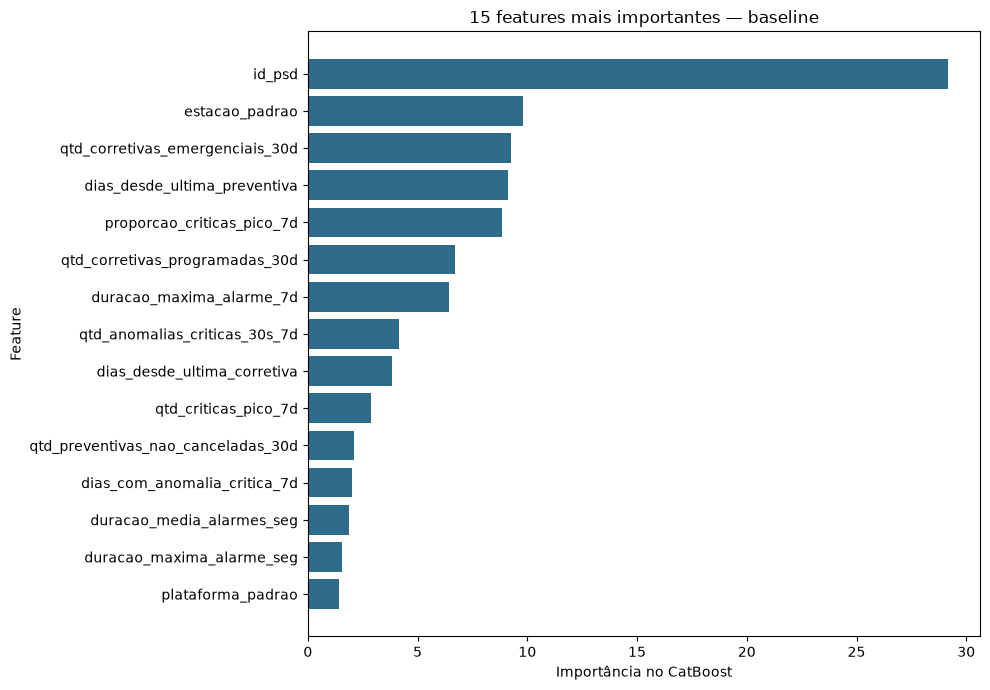

In [12]:
importancias_features = pd.DataFrame({
    "feature": features_modelo,
    "importancia": modelo_baseline.get_feature_importance(),
}).sort_values("importancia", ascending=False).reset_index(drop=True)

display(importancias_features)

top_features = importancias_features.head(15).sort_values("importancia")
plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importancia"], color="#2F6B8A")
plt.xlabel("Importância no CatBoost")
plt.ylabel("Feature")
plt.title("15 features mais importantes — baseline")
plt.tight_layout()
plt.show()

,feature,media_shap_absoluto
0,id_psd,0.2570
1,estacao_padrao,0.1129
2,qtd_corretivas_emergenciais_30d,0.0845
3,proporcao_criticas_pico_7d,0.0828
4,duracao_maxima_alarme_7d,0.0563
5,dias_desde_ultima_preventiva,0.0380
6,qtd_corretivas_programadas_30d,0.0319
7,dias_desde_ultima_corretiva,0.0249
8,qtd_anomalias_criticas_30s_7d,0.0185
9,qtd_criticas_pico_7d,0.0172


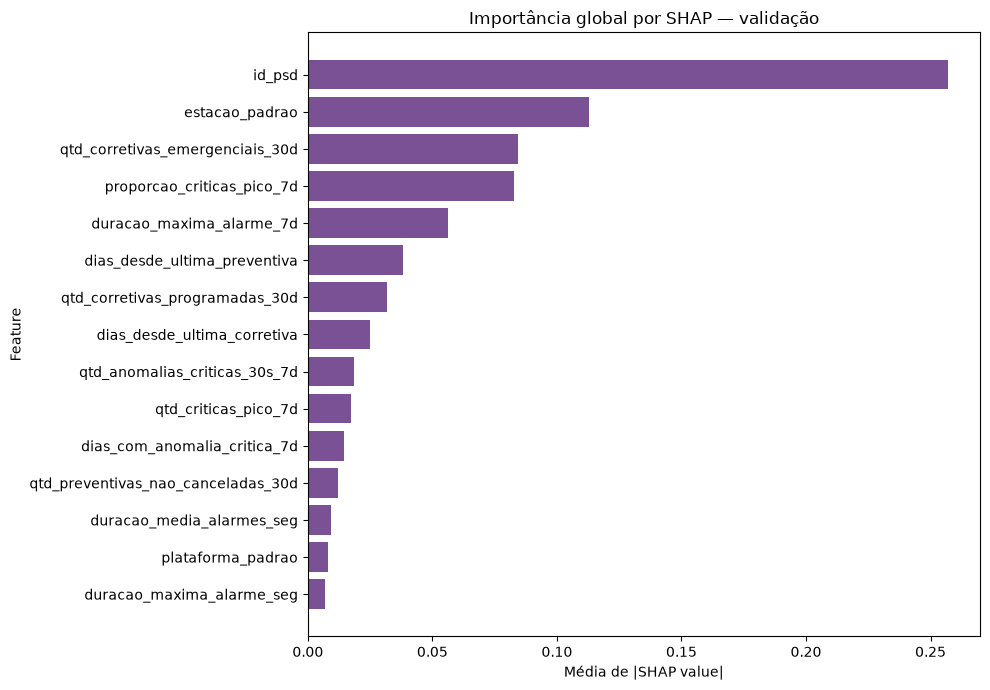

Exemplo: LUZ_P1 em 2025-05-12
Probabilidade prevista: 0.6909
Alvo observado: 1
Valor base SHAP: -0.2178


,feature,valor_observado,shap_value,efeito
0,id_psd,LUZ_P1,0.3217,aumenta o risco
18,qtd_corretivas_emergenciais_30d,23.0,0.2226,aumenta o risco
17,dias_desde_ultima_preventiva,0.0,0.1781,aumenta o risco
15,proporcao_criticas_pico_7d,0.0,0.1065,aumenta o risco
14,duracao_maxima_alarme_7d,0.0,0.0662,aumenta o risco
1,estacao_padrao,LUZ,0.0593,aumenta o risco
13,dias_com_anomalia_critica_7d,0.0,0.0458,aumenta o risco
12,qtd_criticas_pico_7d,0.0,0.0188,aumenta o risco
16,dias_desde_ultima_corretiva,3.0,-0.0182,reduz o risco
11,qtd_anomalias_criticas_30s_7d,0.0,0.0154,aumenta o risco


In [13]:
valores_shap_validacao = modelo_baseline.get_feature_importance(
    pool_validacao,
    type="ShapValues",
)
shap_features = valores_shap_validacao[:, :-1]
valor_base_shap = valores_shap_validacao[:, -1]

importancia_shap = pd.DataFrame({
    "feature": features_modelo,
    "media_shap_absoluto": np.abs(shap_features).mean(axis=0),
}).sort_values("media_shap_absoluto", ascending=False).reset_index(drop=True)

display(importancia_shap)

top_shap = importancia_shap.head(15).sort_values("media_shap_absoluto")
plt.figure(figsize=(10, 7))
plt.barh(top_shap["feature"], top_shap["media_shap_absoluto"], color="#7A5195")
plt.xlabel("Média de |SHAP value|")
plt.ylabel("Feature")
plt.title("Importância global por SHAP — validação")
plt.tight_layout()
plt.show()

indice_exemplo = int(np.argmax(probabilidades_validacao))
explicacao_local = pd.DataFrame({
    "feature": features_modelo,
    "valor_observado": X_validacao.iloc[indice_exemplo].astype(str).values,
    "shap_value": shap_features[indice_exemplo],
})
explicacao_local["efeito"] = np.where(
    explicacao_local["shap_value"] >= 0,
    "aumenta o risco",
    "reduz o risco",
)
explicacao_local = explicacao_local.reindex(
    explicacao_local["shap_value"].abs().sort_values(ascending=False).index
)

print(f"Exemplo: {base_validacao.iloc[indice_exemplo]['id_psd']} em {base_validacao.iloc[indice_exemplo]['data_referencia'].date()}")
print(f"Probabilidade prevista: {probabilidades_validacao[indice_exemplo]:.4f}")
print(f"Alvo observado: {y_validacao.iloc[indice_exemplo]}")
print(f"Valor base SHAP: {valor_base_shap[indice_exemplo]:.4f}")
display(explicacao_local.head(10))

c:\Users\Inteli\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Inteli\AppData\Local\Temp\ipykernel_1488\3541790163.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
c:\Users\Inteli\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


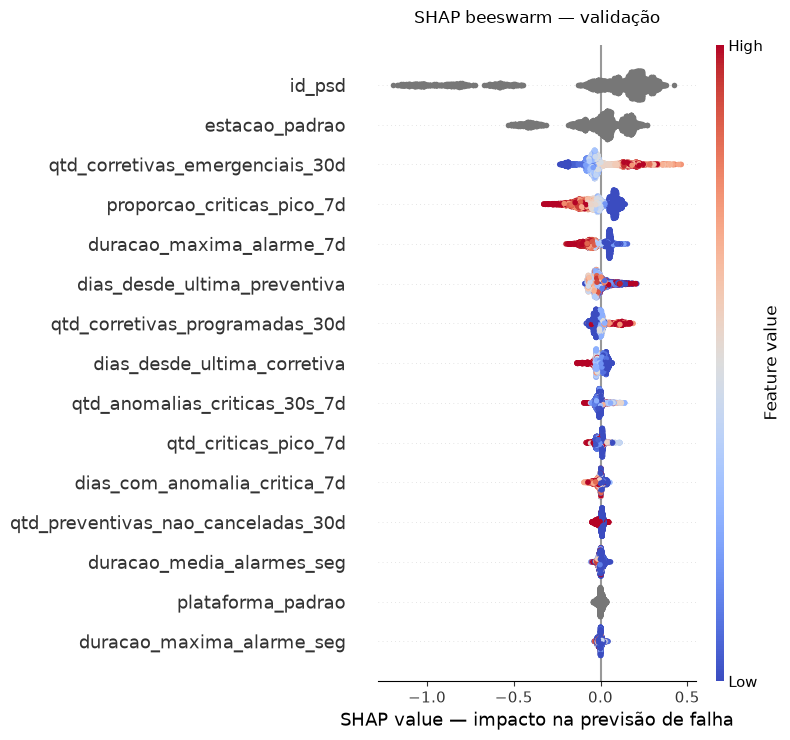

Azul: valor baixo da feature | Vermelho: valor alto da feature
Features categóricas aparecem em cinza porque não possuem uma ordem natural entre baixo e alto.


In [14]:
import shap

X_validacao_shap = X_validacao.copy()
for coluna in features_categoricas:
    X_validacao_shap[coluna] = np.nan

shap.summary_plot(
    shap_features,
    X_validacao_shap,
    feature_names=features_modelo,
    plot_type="dot",
    max_display=15,
    cmap=plt.get_cmap("coolwarm"),
    show=False,
)
plt.title("SHAP beeswarm — validação", pad=16)
plt.xlabel("SHAP value — impacto na previsão de falha")
plt.tight_layout()
plt.show()

print("Azul: valor baixo da feature | Vermelho: valor alto da feature")
print("Features categóricas aparecem em cinza porque não possuem uma ordem natural entre baixo e alto.")